# Statistical process control and fail prediction on SECOM

This notebook works through the public UCI SECOM semiconductor dataset: 1567 production runs,
590 sensor readings per run, and a pass/fail label with a timestamp. It covers a data audit,
control charts with run rules, a capability illustration, and a time-ordered fail predictor.
The analysis code lives in `src/secom_spc/`; this notebook calls it and shows the results.

**What the data is, and is not.** The sensors are anonymized: columns have no names, no units,
and no description of which tool or step produced them. There are no specification limits.
Everything below is therefore about statistical behavior of unnamed numbers, not about a
particular process. Where a result would need engineering context (a spec, a sensor meaning),
the notebook says so instead of inventing one.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.graphics.tsaplots import plot_acf

import secom_spc as sp

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
X, y = sp.load_secom("data")
print(f"seed = {SEED}")
print(f"runs = {len(X)}, sensors = {X.shape[1]}, fails = {y.sum()}")

seed = 42
runs = 1567, sensors = 590, fails = 104


## 1. Data audit

Rows are sorted by timestamp after loading (the file order and the time order are not the same,
and time order is what every later section depends on).

In [2]:
span = X.index.max() - X.index.min()
print(f"first run : {X.index.min()}")
print(f"last run  : {X.index.max()}")
print(f"span      : {span.days} days")
print(f"duplicate timestamps: {X.index.duplicated().sum()} runs share a timestamp with another run")
gaps = X.index.to_series().diff().dropna()
print(f"median gap between runs: {gaps.median()}, longest gap: {gaps.max()}")

n_fail, n_pass = int(y.sum()), int((y == 0).sum())
print(
    f"\npass = {n_pass}, fail = {n_fail}, fail rate = {y.mean():.2%} (about 1 in {1 / y.mean():.0f})"
)

first run : 2008-07-19 11:55:00
last run  : 2008-10-17 06:07:00
span      : 89 days
duplicate timestamps: 33 runs share a timestamp with another run
median gap between runs: 0 days 00:37:00, longest gap: 2 days 00:38:00

pass = 1463, fail = 104, fail rate = 6.64% (about 1 in 15)


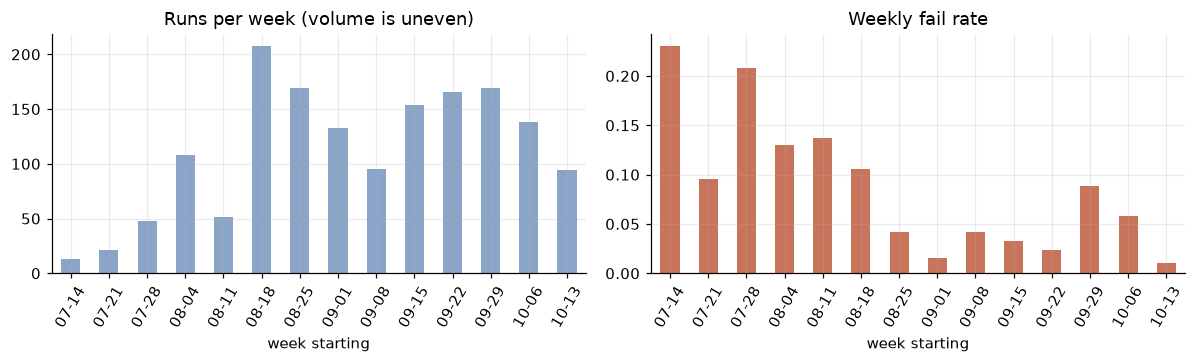

In [3]:
weekly = y.groupby(X.index.to_period("W")).agg(runs="count", fails="sum")
weekly["fail_rate"] = weekly["fails"] / weekly["runs"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
weekly["runs"].plot.bar(ax=ax[0], color="#8aa4c8")
ax[0].set_title("Runs per week (volume is uneven)")
ax[0].set_xticklabels([str(p.start_time.date())[5:] for p in weekly.index], rotation=60)
ax[0].set_xlabel("week starting")
weekly["fail_rate"].plot.bar(ax=ax[1], color="#c8745a")
ax[1].set_title("Weekly fail rate")
ax[1].set_xticklabels([str(p.start_time.date())[5:] for p in weekly.index], rotation=60)
ax[1].set_xlabel("week starting")
plt.tight_layout()
plt.show()

In [4]:
miss = X.isna().mean()
nun = X.nunique()
print("Missingness per sensor")
print(f"  sensors with no missing values : {(miss == 0).sum()}")
print(f"  sensors missing > 5% of runs   : {(miss > 0.05).sum()}")
print(f"  sensors missing > 50% of runs  : {(miss > 0.50).sum()}")
print(f"  worst sensor                   : {miss.idxmax()} ({miss.max():.1%})")
print(f"  share of all cells missing     : {X.isna().to_numpy().mean():.2%}")
print(f"  runs with at least one missing : {X.isna().any(axis=1).mean():.1%}")

print("\nConstant and near-constant sensors")
print(f"  constant (<= 1 distinct value) : {(nun <= 1).sum()}")
print(f"  <= 3 distinct values           : {(nun <= 3).sum()}")
dom = X.apply(lambda c: c.value_counts(normalize=True).iloc[0] if c.notna().any() else np.nan)
print(f"  one value covers >= 99% of runs: {(dom >= 0.99).sum()}")
print(f"  usable continuous (> 100 distinct, < 5% missing): {((nun > 100) & (miss < 0.05)).sum()}")

Missingness per sensor
  sensors with no missing values : 52
  sensors missing > 5% of runs   : 52
  sensors missing > 50% of runs  : 28
  worst sensor                   : s157 (91.2%)
  share of all cells missing     : 4.54%
  runs with at least one missing : 100.0%

Constant and near-constant sensors
  constant (<= 1 distinct value) : 116
  <= 3 distinct values           : 122


  one value covers >= 99% of runs: 122
  usable continuous (> 100 distinct, < 5% missing): 383


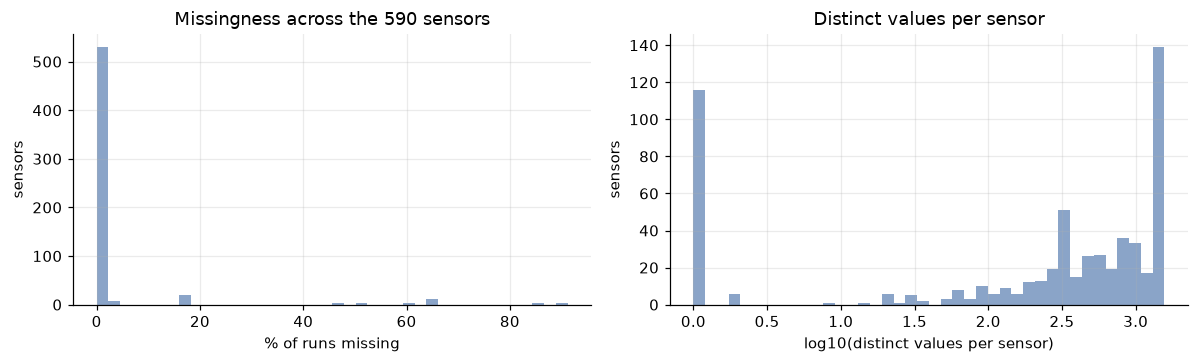

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(miss * 100, bins=40, color="#8aa4c8")
ax[0].set_xlabel("% of runs missing")
ax[0].set_ylabel("sensors")
ax[0].set_title("Missingness across the 590 sensors")
ax[1].hist(np.log10(nun.clip(lower=1)), bins=40, color="#8aa4c8")
ax[1].set_xlabel("log10(distinct values per sensor)")
ax[1].set_ylabel("sensors")
ax[1].set_title("Distinct values per sensor")
plt.tight_layout()
plt.show()

**Reading the audit.** The label is imbalanced at roughly 1 fail in 15 runs, so accuracy is a
useless metric and Section 4 uses precision-recall based measures instead. Missingness is mostly
mild, but a block of sensors is missing in more than half the runs, and over a hundred sensors
carry no information at all (constant). The data is a short snapshot, a bit under three months, with
irregular volume, which limits what drift or seasonality could be seen. Some runs share timestamps,
so the order within a tied timestamp is arbitrary.

## 2. Statistical process control

### Choosing sensors

With 590 unnamed sensors, picking charts by eye is arbitrary. The rule used here, applied to the
**first 70% of runs only** (the same block later used for model training, so no test-period
information leaks into the choice):

1. Eligible: under 1% missing and more than 100 distinct values (continuous, usable on a chart).
2. **Chart A** is the eligible sensor whose values separate fail from pass best on that block
   (largest distance of the Mann-Whitney AUC from 0.5). It is the sensor most worth monitoring if
   fails are what we care about.
3. **Chart B** is the eligible sensor with the highest lag-1 autocorrelation in the phase I window.
   It is deliberately a bad fit for an individuals chart, to show what autocorrelation does.
4. **Chart C** is a well-behaved contrast: the eligible sensor with lag-1 autocorrelation closest to
   zero in the phase I window among sensors whose phase I distribution is not heavily skewed.

In [6]:
N_PHASE1 = 300  # earliest runs, used to estimate limits
n_train = int(np.floor(len(X) * 0.70))  # same 70% boundary as the model in Section 4
Xtr, ytr = X.iloc[:n_train], y.iloc[:n_train]

eligible = [c for c in X.columns if miss[c] < 0.01 and nun[c] > 100]


def auc_distance(col):
    v = Xtr[col]
    ok = v.notna()
    u = stats.mannwhitneyu(v[ok & (ytr == 1)], v[ok & (ytr == 0)]).statistic
    auc = u / ((ok & (ytr == 1)).sum() * (ok & (ytr == 0)).sum())
    return abs(auc - 0.5)


sel = pd.DataFrame(
    {
        "auc_dist": {c: auc_distance(c) for c in eligible},
        "lag1_p1": {c: sp.lag1_autocorrelation(X[c].iloc[:N_PHASE1]) for c in eligible},
        "skew_p1": {c: stats.skew(X[c].iloc[:N_PHASE1].dropna()) for c in eligible},
    }
)
A = sel["auc_dist"].idxmax()
B = sel["lag1_p1"].idxmax()
calm = sel[sel["skew_p1"].abs() < 0.5]
C = calm["lag1_p1"].abs().idxmin()
print(
    f"eligible sensors: {len(eligible)}; phase I = first {N_PHASE1} runs "
    f"({X.index[0].date()} to {X.index[N_PHASE1 - 1].date()}), fails in window: {int(y.iloc[:N_PHASE1].sum())}"
)
chosen = {"A": A, "B": B, "C": C}
print(sel.loc[list(chosen.values())].assign(chart=list(chosen)).round(3).to_string())

eligible sensors: 337; phase I = first 300 runs (2008-07-19 to 2008-08-19), fails in window: 44
      auc_dist  lag1_p1  skew_p1 chart
s059     0.256    0.176    0.199     A
s405     0.024    0.854   -0.089     B
s001     0.009    0.001    0.235     C


### Autocorrelation check before trusting limits

I-MR limits assume successive points are independent. If they are not, the moving range
understates the true spread and the chart raises false alarms. The check below uses the phase I
window only (that is the data the limits are estimated from).

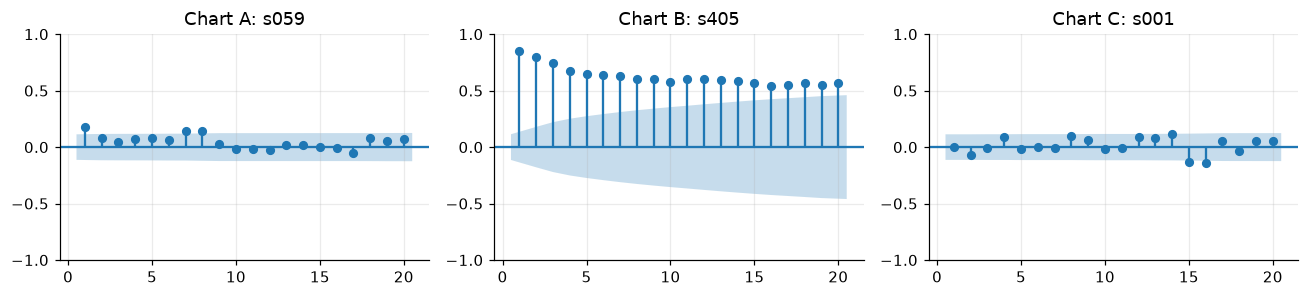

chart sensor  lag1_acf  sigma_from_MR  sample_sd  sd_over_sigmaMR
    A   s059     0.176         10.769     13.130            1.219
    B   s405     0.854          0.003      0.009            3.538
    C   s001     0.001         83.559     89.641            1.073


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(12, 2.8))
for a, (tag, col) in zip(ax, chosen.items(), strict=False):
    plot_acf(
        X[col].iloc[:N_PHASE1].dropna(), lags=20, ax=a, title=f"Chart {tag}: {col}", zero=False
    )
plt.tight_layout()
plt.show()

rows = []
for tag, col in chosen.items():
    p1 = X[col].iloc[:N_PHASE1]
    lim = sp.estimate_imr_limits(p1)
    sd = p1.std()
    rows.append(
        {
            "chart": tag,
            "sensor": col,
            "lag1_acf": sp.lag1_autocorrelation(p1),
            "sigma_from_MR": lim.sigma,
            "sample_sd": sd,
            "sd_over_sigmaMR": sd / lim.sigma,
        }
    )
print(pd.DataFrame(rows).round(3).to_string(index=False))

If the sample standard deviation is well above the moving-range sigma, successive points are
positively correlated or the window contains a shift, and 3-sigma limits built from the moving
range are too narrow. That is the case for chart B. Chart A is mildly autocorrelated and chart C is essentially independent, so their limits are usable as
an approximation. Chart B is kept in the notebook as the cautionary example, not as a monitoring
recommendation.

### I-MR charts with phase I limits and phase II monitoring

Limits are fixed from the first 300 runs and then held constant. Everything after that is phase II.
Rule violations use Western Electric rules WE1 to WE4 (beyond 3 sigma; 2 of 3 beyond 2 sigma;
4 of 5 beyond 1 sigma; 8 in a row on one side) plus Nelson's trend (6 steadily rising or falling)
and alternation (14 alternating) rules. A flag marks the point where the pattern completes.
Fail runs are drawn as red marks so the chart can be compared with the label, not used to build it.

In [8]:
RULE_COLORS = {
    "WE1": "#d62728",
    "WE2": "#ff7f0e",
    "WE3": "#bcbd22",
    "WE4": "#9467bd",
    "N5": "#17becf",
    "N6": "#7f7f7f",
}


def imr_chart(col, tag, save=None):
    s = X[col]
    lim = sp.estimate_imr_limits(s.iloc[:N_PHASE1])
    flags = sp.check_rules(s.to_numpy(), lim.center, lim.sigma)
    flags.index = s.index
    idx = np.arange(len(s))
    mr = s.diff().abs()
    fig, ax = plt.subplots(
        2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1.4]}
    )
    a = ax[0]
    a.plot(idx, s.to_numpy(), lw=0.6, color="#3b5b92")
    for k in (1, 2, 3):
        for sign in (1, -1):
            a.axhline(
                lim.center + sign * k * lim.sigma,
                color="#444",
                lw=0.8 if k == 3 else 0.5,
                ls="-" if k == 3 else ":",
            )
    a.axhline(lim.center, color="#2a7f3f", lw=1)
    a.axvspan(0, N_PHASE1, color="#2a7f3f", alpha=0.08)
    a.text(N_PHASE1 / 2, a.get_ylim()[1], "phase I", ha="center", va="top", fontsize=9)
    for rule, color in RULE_COLORS.items():
        hit = flags[rule].to_numpy()
        a.scatter(
            idx[hit], s.to_numpy()[hit], s=14, color=color, label=f"{rule} ({hit.sum()})", zorder=3
        )
    fails = (y.to_numpy() == 1) & s.notna().to_numpy()
    a.scatter(
        idx[fails],
        np.full(fails.sum(), a.get_ylim()[0]),
        marker="|",
        s=60,
        color="#b00020",
        label="fail run (label)",
        zorder=2,
    )
    a.set_title(f"Chart {tag}: individuals, sensor {col}  (limits from runs 1 to {N_PHASE1})")
    a.legend(ncol=4, fontsize=8, loc="upper right", framealpha=0.9)
    b = ax[1]
    b.plot(idx, mr.to_numpy(), lw=0.6, color="#3b5b92")
    b.axhline(lim.mr_bar, color="#2a7f3f", lw=1)
    b.axhline(lim.mr_ucl, color="#444", lw=0.8)
    b.axvspan(0, N_PHASE1, color="#2a7f3f", alpha=0.08)
    b.set_ylabel("moving range")
    b.set_xlabel("run number (time order)")
    plt.tight_layout()
    if save:
        fig.savefig(save, dpi=130, facecolor="white")
    plt.show()
    return lim, flags


def flag_summary(col, lim, flags):
    out = []
    for name, sl in (("phase I", slice(0, N_PHASE1)), ("phase II", slice(N_PHASE1, None))):
        f = flags.iloc[sl]
        out.append(
            {
                "window": name,
                "runs": len(f),
                **{r: int(f[r].sum()) for r in f.columns},
                "any_rule": int(f.any(axis=1).sum()),
            }
        )
    return pd.DataFrame(out)

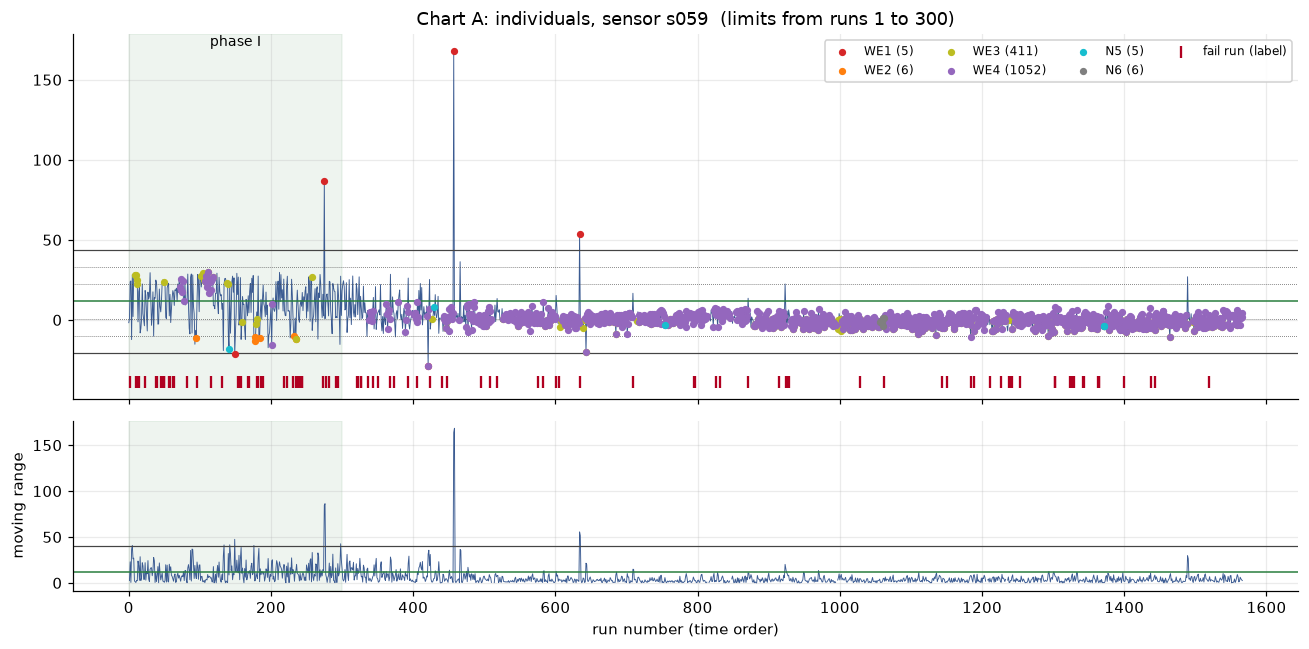

limits: center=11.65, sigma=10.77, UCL=43.95, LCL=-20.66
  window  runs  WE1  WE2  WE3  WE4  N5  N6  any_rule
 phase I   300    2    6   22   20   1   0        44
phase II  1267    3    0  389 1032   4   6      1051


In [9]:
limA, flagsA = imr_chart(A, "A", save="figures/imr_chart_a.png")
print(
    f"limits: center={limA.center:.4g}, sigma={limA.sigma:.4g}, UCL={limA.ucl:.4g}, LCL={limA.lcl:.4g}"
)
print(flag_summary(A, limA, flagsA).to_string(index=False))

In [10]:
blk = (
    pd.DataFrame({"v": X[A], "fail": y})
    .groupby(np.arange(len(X)) // 150)
    .agg(
        first_run=("v", lambda s: s.index[0].date()),
        median=("v", "median"),
        fail_rate=("fail", "mean"),
    )
)
blk.index.name = "block of 150 runs"
print(f"Sensor {A}: median value and fail rate by consecutive block of 150 runs")
print(blk.round(3).to_string())

Sensor s059: median value and fail rate by consecutive block of 150 runs
                    first_run  median  fail_rate
block of 150 runs                               
0                  2008-07-19  17.467      0.127
1                  2008-08-07   8.752      0.167
2                  2008-08-19   3.282      0.093
3                  2008-08-27   1.091      0.033
4                  2008-08-31   0.544      0.027
5                  2008-09-07   1.576      0.033
6                  2008-09-19  -1.194      0.033
7                  2008-09-24  -0.727      0.033
8                  2008-09-30   0.150      0.100
9                  2008-10-06  -1.470      0.040
10                 2008-10-14  -0.226      0.015


**Chart A is not a clean in-control story.** The table above shows the sensor's level falling steadily over the
first several blocks while the fail rate falls with it. Two things follow. First, the phase I window
is not a stable baseline for this sensor: its level is still moving, so the pile of WE3 and WE4
flags in phase II mostly records that the level settled lower than where it started, not a string
of special causes. Second, the strong fail/pass separation that led to choosing this sensor is
at least partly a shared time trend: early runs both read high and fail more often. Time is a confound
here, which is a reason to distrust any model that leans on it.

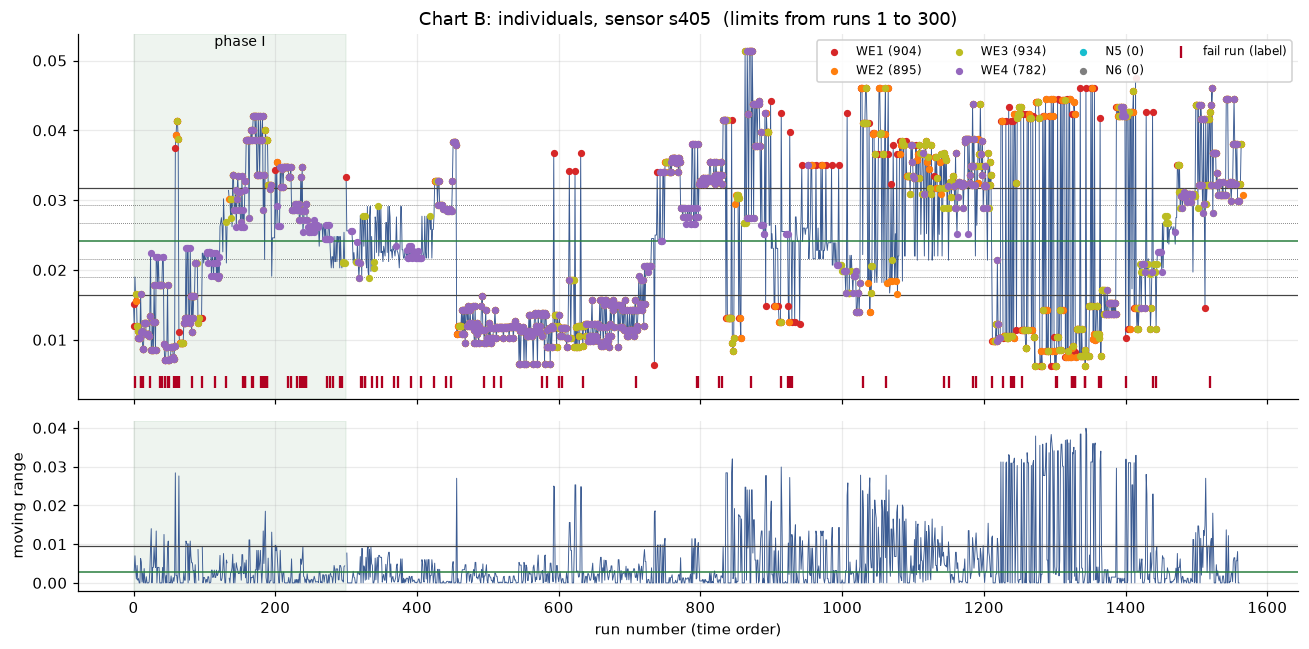

limits: center=0.02412, sigma=0.00256
  window  runs  WE1  WE2  WE3  WE4  N5  N6  any_rule
 phase I   300  126  133  153  202   0   0       242
phase II  1267  778  762  781  580   0   0      1031


In [11]:
limB, flagsB = imr_chart(B, "B")
print(f"limits: center={limB.center:.4g}, sigma={limB.sigma:.4g}")
print(flag_summary(B, limB, flagsB).to_string(index=False))

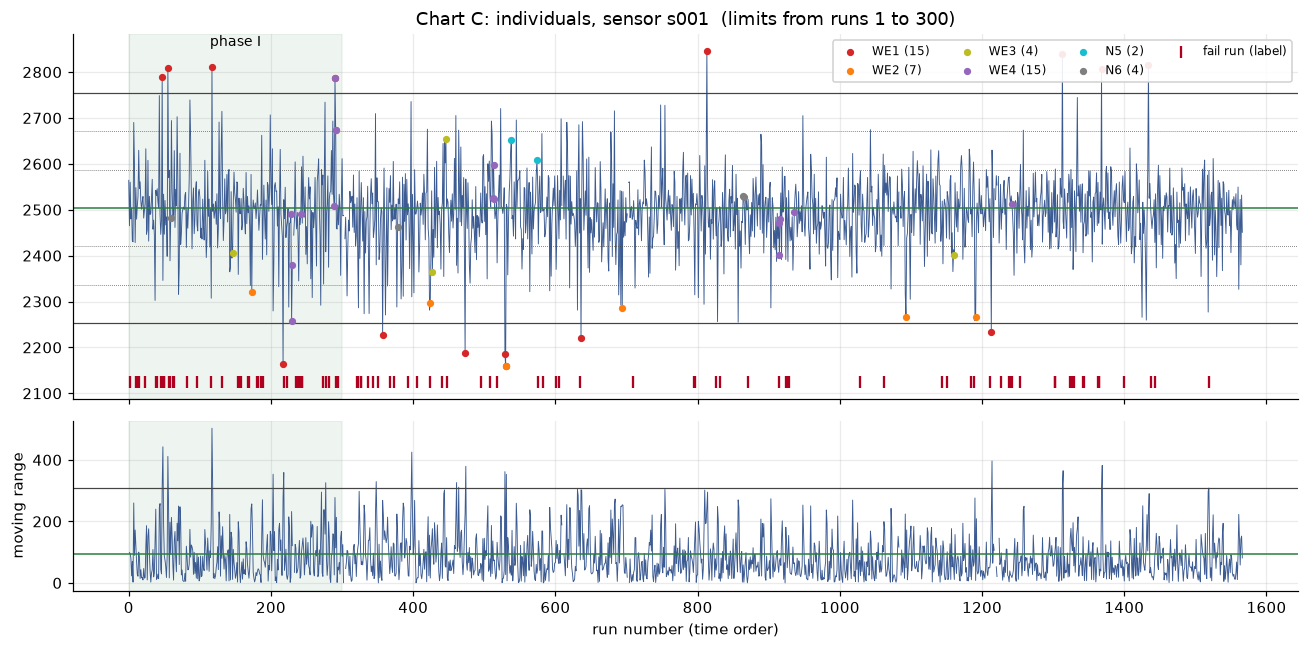

limits: center=2504, sigma=83.56
  window  runs  WE1  WE2  WE3  WE4  N5  N6  any_rule
 phase I   300    5    2    1    7   0   1        14
phase II  1267   10    5    3    8   2   3        30


In [12]:
limC, flagsC = imr_chart(C, "C")
print(f"limits: center={limC.center:.4g}, sigma={limC.sigma:.4g}")
print(flag_summary(C, limC, flagsC).to_string(index=False))

**Do the flags line up with failures?** Control chart alarms say a sensor moved; they do not say a
run failed. The next cell measures that directly in phase II: of the runs a chart flagged, what
share were fails, against the phase II base rate.

In [13]:
rows = []
y2 = y.iloc[N_PHASE1:]
for tag, fl in (("A", flagsA), ("B", flagsB), ("C", flagsC)):
    anyf = fl.iloc[N_PHASE1:].any(axis=1).to_numpy()
    rows.append(
        {
            "chart": tag,
            "phase II runs": len(y2),
            "flagged runs": int(anyf.sum()),
            "fail rate among flagged": y2[anyf].mean() if anyf.any() else np.nan,
            "fail rate among unflagged": y2[~anyf].mean(),
            "phase II base rate": y2.mean(),
        }
    )
print(pd.DataFrame(rows).round(3).to_string(index=False))

chart  phase II runs  flagged runs  fail rate among flagged  fail rate among unflagged  phase II base rate
    A           1267          1051                    0.038                      0.093               0.047
    B           1267          1031                    0.047                      0.051               0.047
    C           1267            30                    0.100                      0.046               0.047


### EWMA on one sensor

An EWMA (lambda 0.2, 3-sigma limits) is more sensitive than the individuals chart to small
sustained shifts. It is run on chart A's sensor with the same phase I center and sigma. A CUSUM
(k = 0.5, h = 5) on the same sensor is shown as a cross-check; both use sigma estimated from the
moving range.

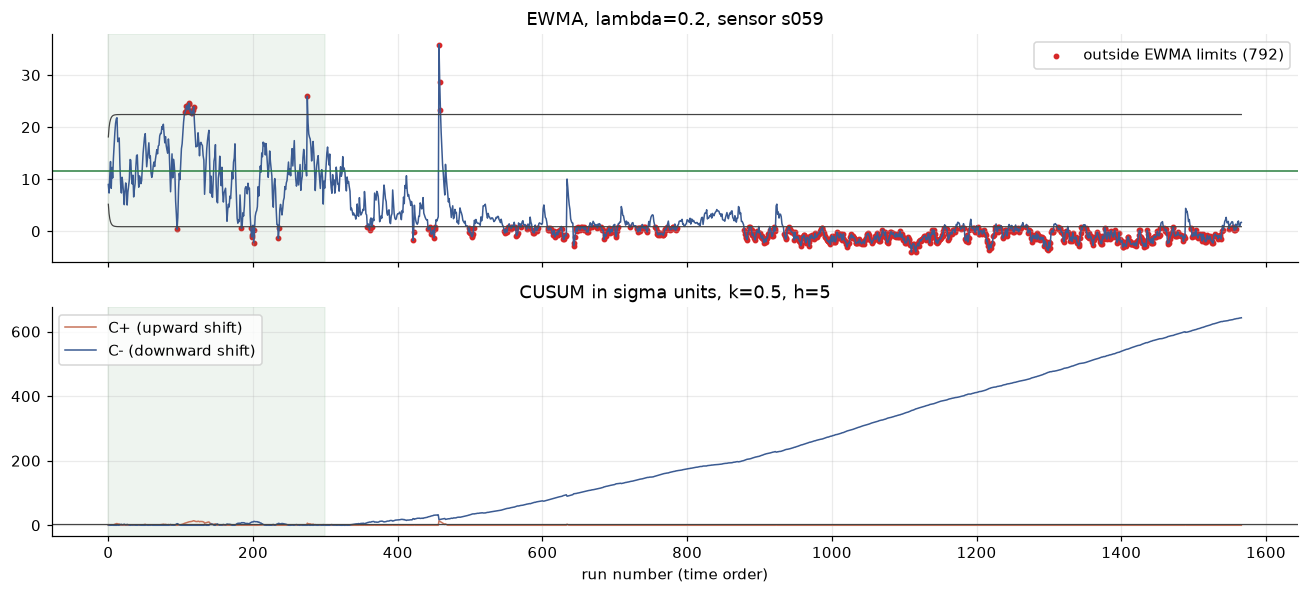

EWMA points outside limits: phase I = 22, phase II = 770 of 1267
CUSUM alarm points:         phase I = 75, phase II = 1219
first phase II run number to alarm: EWMA = 358, CUSUM = 346, I-chart WE1 = 421


In [14]:
s = X[A]
LAM = 0.2
z = sp.ewma(s, limA.center, LAM)
lo, hi = sp.ewma_limits(limA.center, limA.sigma, len(s), LAM)
out = (z.to_numpy() < lo) | (z.to_numpy() > hi)
cus = sp.cusum(s, limA.center, limA.sigma)

fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
idx = np.arange(len(s))
ax[0].plot(idx, z.to_numpy(), color="#3b5b92", lw=1)
ax[0].plot(idx, hi, color="#444", lw=0.8)
ax[0].plot(idx, lo, color="#444", lw=0.8)
ax[0].axhline(limA.center, color="#2a7f3f", lw=1)
ax[0].scatter(
    idx[out], z.to_numpy()[out], s=8, color="#d62728", label=f"outside EWMA limits ({out.sum()})"
)
ax[0].axvspan(0, N_PHASE1, color="#2a7f3f", alpha=0.08)
ax[0].set_title(f"EWMA, lambda={LAM}, sensor {A}")
ax[0].legend(loc="upper right")
ax[1].plot(idx, cus["c_plus"], color="#c8745a", lw=1, label="C+ (upward shift)")
ax[1].plot(idx, cus["c_minus"], color="#3b5b92", lw=1, label="C- (downward shift)")
ax[1].axhline(5, color="#444", lw=0.8)
ax[1].axvspan(0, N_PHASE1, color="#2a7f3f", alpha=0.08)
ax[1].set_title("CUSUM in sigma units, k=0.5, h=5")
ax[1].set_xlabel("run number (time order)")
ax[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

first_ewma = int(np.argmax(out[N_PHASE1:])) + N_PHASE1 if out[N_PHASE1:].any() else None
first_cusum = (
    int(np.argmax(cus["alarm"].to_numpy()[N_PHASE1:])) + N_PHASE1
    if cus["alarm"].iloc[N_PHASE1:].any()
    else None
)
first_imr = (
    int(np.argmax(flagsA["WE1"].to_numpy()[N_PHASE1:])) + N_PHASE1
    if flagsA["WE1"].iloc[N_PHASE1:].any()
    else None
)
print(
    f"EWMA points outside limits: phase I = {out[:N_PHASE1].sum()}, phase II = {out[N_PHASE1:].sum()} of {len(s) - N_PHASE1}"
)
print(
    f"CUSUM alarm points:         phase I = {int(cus['alarm'].iloc[:N_PHASE1].sum())}, phase II = {int(cus['alarm'].iloc[N_PHASE1:].sum())}"
)
print(
    f"first phase II run number to alarm: EWMA = {first_ewma}, CUSUM = {first_cusum}, I-chart WE1 = {first_imr}"
)

**Reading Section 2.** The phase II flag rates in the table above, compared with the nominal rates
expected from in-control normal data, show how stable the process is relative to its first weeks.
The EWMA and CUSUM views show whether the sensor drifted away from its phase I level rather than
only spiking. The caveat for every chart: SECOM has one pooled stream with no known product, tool,
or recipe changes, so a flag can reflect a product mix change rather than a fault. Without
engineering context these are leads, not diagnoses.

## 3. Process capability

**SECOM contains no specification limits.** Cp, Cpk, Pp and Ppk are defined relative to a lower
and upper spec limit, so none of them can be computed for this data as a statement about the real
process. What follows is a demonstration of the calculation only.

The limits below are **ASSUMED, ILLUSTRATIVE** values: the phase I center plus and minus four
phase I sample standard deviations. They are made up to show how the indices respond when a process
shifts, and they say nothing about whether a real part would pass. Two methods are shown: the
usual normal-theory indices, and a nonparametric percentile method that does not assume a bell
curve.

In [15]:
rows = []
for tag, col in chosen.items():
    p1 = X[col].iloc[:N_PHASE1]
    lsl = p1.mean() - 4 * p1.std()  # ASSUMED, not a real spec
    usl = p1.mean() + 4 * p1.std()  # ASSUMED, not a real spec
    for name, window in (("phase I", X[col].iloc[:N_PHASE1]), ("phase II", X[col].iloc[N_PHASE1:])):
        cap = sp.capability_indices(window, lsl, usl)
        npc = sp.nonparametric_capability(window, lsl, usl)
        rows.append(
            {
                "chart": tag,
                "sensor": col,
                "window": name,
                "ASSUMED LSL": lsl,
                "ASSUMED USL": usl,
                "Cp": cap["cp"],
                "Cpk": cap["cpk"],
                "Pp": cap["pp"],
                "Ppk": cap["ppk"],
                "Ppk (percentile)": npc["ppk"],
                "skew": stats.skew(window.dropna()),
            }
        )
cap_table = pd.DataFrame(rows)
print("ASSUMED limits = phase I mean +/- 4 phase I sample SD. Illustration only.\n")
print(cap_table.round(3).to_string(index=False))

ASSUMED limits = phase I mean +/- 4 phase I sample SD. Illustration only.

chart sensor   window  ASSUMED LSL  ASSUMED USL    Cp   Cpk    Pp   Ppk  Ppk (percentile)   skew
    A   s059  phase I      -40.872       64.167 1.626 1.626 1.333 1.333             1.005  0.199
    A   s059 phase II      -40.872       64.167 4.245 3.375 2.493 1.983             1.547 11.672
    B   s405  phase I       -0.012        0.060 4.718 4.718 1.333 1.333             2.067 -0.089
    B   s405 phase II       -0.012        0.060 2.385 2.378 1.090 1.087             1.320  0.266
    C   s001  phase I     2145.332     2862.462 1.430 1.430 1.333 1.333             1.171  0.235
    C   s001 phase II     2145.332     2862.462 1.630 1.584 1.533 1.490             1.123 -0.166


Cp and Cpk use the moving-range sigma (short-term variation). Pp and Ppk use the overall sample
standard deviation (long-term). A large gap between them points to drift or autocorrelation, which
is the pattern in chart B. Phase I Ppk is near 1.3 by construction (four sigma to each limit, in
sigma-from-standard-deviation terms), so the interesting column is how far phase II moves from
that. A Ppk drop in phase II would be a statement about movement away from phase I, and only that.
The percentile column matters when a sensor is skewed; a normal-theory index misstates tail risk
there.

## 4. Predicting fail

**Design choices, fixed before looking at the test block:**

- **Time-ordered split.** The first 70% of runs (by timestamp) form the training block, the last
  30% the test block. Nothing is shuffled, so no later run informs an earlier prediction.
- **Inside the training block**, the first 80% fit the model and the last 20% (still earlier than any
  test run) is a validation block used only to set the alarm threshold.
- **Preprocessing fit on the fitting block only.** Sensors with no variation in the fitting block are dropped, missing values
  are median-imputed, and features are standardized, all with statistics from the fitting block.
- **Imbalance.** Both models use balanced class weights.
- **Models.** Logistic regression (L2, C = 0.01) as the baseline against histogram gradient boosting
  (shallow trees, 150 iterations, learning rate 0.05). Hyperparameters were set once by judgment and
  never adjusted after seeing any score. There is no tuning on the test block.
- **Operating point.** The alarm threshold is the score that would flag 5% of pass runs in the
  validation block. The same threshold is then applied to the test block, so the false-alarm rate
  actually realized on test can differ from 5%, and the report shows it.
- **Uncertainty.** 95% percentile bootstrap intervals (2000 resamples of test runs, seed 42).

In [16]:
tr_idx, te_idx = sp.time_split(len(X), 0.70)
fit_idx = tr_idx[: int(np.floor(len(tr_idx) * 0.80))]
val_idx = tr_idx[len(fit_idx) :]
print(
    f"fit  : runs {fit_idx[0]}..{fit_idx[-1]}  {X.index[fit_idx[0]].date()} to {X.index[fit_idx[-1]].date()}  "
    f"n={len(fit_idx)}, fails={int(y.iloc[fit_idx].sum())}"
)
print(
    f"val  : runs {val_idx[0]}..{val_idx[-1]}  {X.index[val_idx[0]].date()} to {X.index[val_idx[-1]].date()}  "
    f"n={len(val_idx)}, fails={int(y.iloc[val_idx].sum())}"
)
print(
    f"test : runs {te_idx[0]}..{te_idx[-1]}  {X.index[te_idx[0]].date()} to {X.index[te_idx[-1]].date()}  "
    f"n={len(te_idx)}, fails={int(y.iloc[te_idx].sum())}"
)
assert X.index[fit_idx[-1]] <= X.index[val_idx[0]] <= X.index[val_idx[-1]] <= X.index[te_idx[0]]

keep = X.iloc[fit_idx].columns[X.iloc[fit_idx].nunique() > 1]
print(f"sensors kept (vary in fit block): {len(keep)} of {X.shape[1]}")
Xf, Xv, Xt = X.iloc[fit_idx][keep], X.iloc[val_idx][keep], X.iloc[te_idx][keep]
yf, yv, yt = y.iloc[fit_idx].to_numpy(), y.iloc[val_idx].to_numpy(), y.iloc[te_idx].to_numpy()

fit  : runs 0..875  2008-07-19 to 2008-09-18  n=876, fails=72
val  : runs 876..1095  2008-09-18 to 2008-09-26  n=220, fails=6
test : runs 1096..1566  2008-09-26 to 2008-10-17  n=471, fails=26
sensors kept (vary in fit block): 468 of 590


In [17]:
models = {
    "Logistic regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(C=0.01, class_weight="balanced", max_iter=2000, random_state=SEED),
    ),
    "Gradient boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingClassifier(
            max_depth=3,
            max_iter=150,
            learning_rate=0.05,
            class_weight="balanced",
            random_state=SEED,
        ),
    ),
}
FPR_TARGET = 0.05
results, scores = {}, {}
for name, model in models.items():
    model.fit(Xf, yf)
    sv = model.predict_proba(Xv)[:, 1]
    st = model.predict_proba(Xt)[:, 1]
    thr = sp.threshold_for_fpr(sv[yv == 0], FPR_TARGET)
    rec, fpr = sp.recall_at_fpr(yt, st, thr)
    ap = average_precision_score(yt, st)
    ap_ci = sp.bootstrap_ci(yt, st, average_precision_score, n_boot=2000, seed=SEED)
    rec_ci = sp.bootstrap_ci(
        yt, st, lambda a, b, t=thr: sp.recall_at_fpr(a, b, t)[0], n_boot=2000, seed=SEED
    )
    fpr_ci = sp.bootstrap_ci(
        yt, st, lambda a, b, t=thr: sp.recall_at_fpr(a, b, t)[1], n_boot=2000, seed=SEED
    )
    cm = confusion_matrix(yt, st >= thr)
    scores[name] = st
    results[name] = dict(
        thr=thr, ap=ap, ap_ci=ap_ci, rec=rec, rec_ci=rec_ci, fpr=fpr, fpr_ci=fpr_ci, cm=cm
    )

prevalence = yt.mean()
print(f"test prevalence (no-skill PR-AUC) = {prevalence:.3f}\n")
for name, r in results.items():
    print(f"{name}")
    print(
        f"  PR-AUC (average precision) : {r['ap']:.3f}  95% CI [{r['ap_ci'][0]:.3f}, {r['ap_ci'][1]:.3f}]"
    )
    print(
        f"  recall at threshold        : {r['rec']:.3f}  95% CI [{r['rec_ci'][0]:.3f}, {r['rec_ci'][1]:.3f}]"
    )
    print(
        f"  realized false-alarm rate  : {r['fpr']:.3f}  95% CI [{r['fpr_ci'][0]:.3f}, {r['fpr_ci'][1]:.3f}]  (target {FPR_TARGET})"
    )
    tn, fp, fn, tp = r["cm"].ravel()
    print(f"  confusion matrix (test)    : TN={tn} FP={fp} FN={fn} TP={tp}\n")

test prevalence (no-skill PR-AUC) = 0.055

Logistic regression
  PR-AUC (average precision) : 0.064  95% CI [0.041, 0.110]
  recall at threshold        : 0.000  95% CI [0.000, 0.000]
  realized false-alarm rate  : 0.036  95% CI [0.020, 0.054]  (target 0.05)
  confusion matrix (test)    : TN=429 FP=16 FN=26 TP=0

Gradient boosting
  PR-AUC (average precision) : 0.085  95% CI [0.052, 0.167]
  recall at threshold        : 0.077  95% CI [0.000, 0.200]
  realized false-alarm rate  : 0.036  95% CI [0.020, 0.054]  (target 0.05)
  confusion matrix (test)    : TN=429 FP=16 FN=24 TP=2



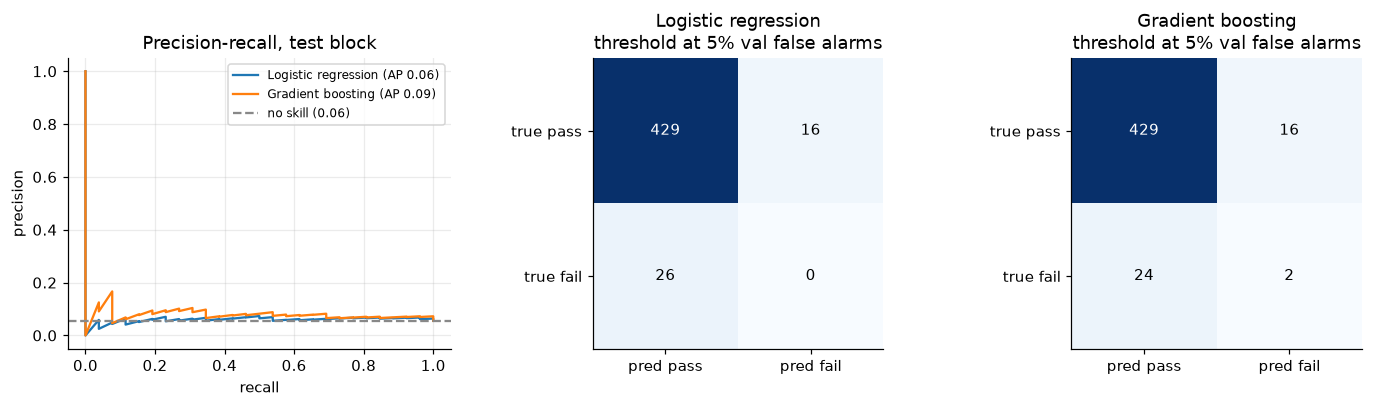

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for name, st in scores.items():
    p, r_, _ = precision_recall_curve(yt, st)
    ax[0].plot(r_, p, label=f"{name} (AP {results[name]['ap']:.2f})")
ax[0].axhline(prevalence, color="#888", ls="--", label=f"no skill ({prevalence:.2f})")
ax[0].set_xlabel("recall")
ax[0].set_ylabel("precision")
ax[0].set_title("Precision-recall, test block")
ax[0].legend(fontsize=8)
for a, (name, r) in zip(ax[1:], results.items(), strict=False):
    cm = r["cm"]
    a.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        a.text(
            j, i, str(v), ha="center", va="center", color="white" if v > cm.max() / 2 else "black"
        )
    a.set_xticks([0, 1], ["pred pass", "pred fail"])
    a.set_yticks([0, 1], ["true pass", "true fail"])
    a.set_title(f"{name}\nthreshold at 5% val false alarms")
    a.grid(False)
plt.tight_layout()
plt.savefig("figures/model_pr_confusion.png", dpi=130, facecolor="white")
plt.show()

### Is there any usable signal?

Intervals from 26 test fails are wide, and a point estimate above the no-skill line is not
evidence by itself. The permutation check below shuffles the test labels 1000 times (seeded) to see
how often a model with no information would reach the observed PR-AUC.

In [19]:
rng = np.random.default_rng(SEED)
perm = {}
for name, st in scores.items():
    null = np.array([average_precision_score(rng.permutation(yt), st) for _ in range(1000)])
    perm[name] = (null.mean(), np.quantile(null, 0.95), (null >= results[name]["ap"]).mean())
    print(
        f"{name}: observed AP {results[name]['ap']:.3f}; label-shuffle mean {null.mean():.3f}, "
        f"95th percentile {np.quantile(null, 0.95):.3f}; share of shuffles >= observed: {perm[name][2]:.3f}"
    )

Logistic regression: observed AP 0.064; label-shuffle mean 0.064, 95th percentile 0.090; share of shuffles >= observed: 0.430


Gradient boosting: observed AP 0.085; label-shuffle mean 0.068, 95th percentile 0.107; share of shuffles >= observed: 0.151


**Reading Section 4.** The result is weak, and the notebook reports it that way. Neither model
separates itself from chance on the test block. Each PR-AUC interval includes or sits just above
the no-skill prevalence, and each observed PR-AUC falls inside the label-shuffle range (the share of
shuffles that match or beat it is shown above, and is not small). At the validation-chosen threshold,
logistic regression catches none of the test fails and gradient boosting catches a couple, with the
confusion matrices showing how few. Fail rate also falls from the earlier blocks to the later ones,
so a model trained on the early period faces a shifted base rate at test time. Nothing was tuned on
the test block, so these numbers are a fair estimate of a weak result, not a pessimistic one.
Gradient boosting scoring a little higher than logistic regression here is within noise.

## 5. Findings and what an engineer would do next

In [20]:
rows = []
for tag, fl in (("A", flagsA), ("B", flagsB), ("C", flagsC)):
    f2 = fl.iloc[N_PHASE1:]
    rows.append(
        {
            "chart": tag,
            "phase II any-rule flag rate": f2.any(axis=1).mean(),
            "phase II WE1 rate": f2["WE1"].mean(),
            "nominal WE1 rate": 0.0027,
        }
    )
print("Headline summary (all values from the cells above)")
print(
    f"seed = {SEED}; runs = {len(X)}; sensors = {X.shape[1]}; fails = {int(y.sum())} ({y.mean():.2%})"
)
print(
    f"constant sensors = {int((nun <= 1).sum())}; sensors missing >50% = {int((miss > 0.5).sum())}"
)
print(f"chart sensors: A = {A}, B = {B}, C = {C}")
print(pd.DataFrame(rows).round(3).to_string(index=False))
for name, r in results.items():
    print(
        f"{name}: PR-AUC {r['ap']:.3f} [{r['ap_ci'][0]:.3f}, {r['ap_ci'][1]:.3f}] vs no-skill {prevalence:.3f}; "
        f"recall {r['rec']:.3f} at realized false-alarm rate {r['fpr']:.3f}"
    )

Headline summary (all values from the cells above)
seed = 42; runs = 1567; sensors = 590; fails = 104 (6.64%)
constant sensors = 116; sensors missing >50% = 28
chart sensors: A = s059, B = s405, C = s001
chart  phase II any-rule flag rate  phase II WE1 rate  nominal WE1 rate
    A                        0.830              0.002             0.003
    B                        0.814              0.614             0.003
    C                        0.024              0.008             0.003
Logistic regression: PR-AUC 0.064 [0.041, 0.110] vs no-skill 0.055; recall 0.000 at realized false-alarm rate 0.036
Gradient boosting: PR-AUC 0.085 [0.052, 0.167] vs no-skill 0.055; recall 0.077 at realized false-alarm rate 0.036


**What the data supports.**

- The data is a snapshot of under three months with about 1 fail in 15 runs, and a large share of
  sensors are constant or mostly missing. Cleaning and sensor triage come before any modeling.
- Individuals charts are usable on some sensors and misleading on others. Autocorrelation has to be
  checked first; on strongly autocorrelated sensors the limits are too tight and the alarms mostly
  reflect slow movement, not special causes.
- Capability numbers cannot be reported without specs. The assumed-limit demonstration shows
  the mechanics only.
- The fail predictor is weak and does not clearly beat label shuffling on the test block. The honest
  summary is the interval and shuffle comparison above, not the point estimate.
- Time is entangled with everything: sensor levels drift and the fail rate declines over the same weeks.
  Any association found without controlling for time may be a calendar effect.

**What an engineer would do next.**

1. Get sensor names, units and the process step each column comes from. Group sensors by tool and step
   and chart them separately; one pooled stream hides tool-to-tool differences.
2. Get real spec limits and the meaning of the fail label (final test, inline metrology, yield bin).
   Then Cp and Cpk become real numbers instead of an illustration.
3. Investigate the runs flagged by WE1 and EWMA in phase II against maintenance logs, lot and recipe
   changes. A flag is a lead; the logbook decides.
4. Collect more fails. With roughly a hundred, no model comparison is conclusive. Pool more weeks,
   or move to a grouped design (by lot or tool) so train and test do not share a lot.
5. If prediction is still the goal, use the sensors that chart flags point to as a short candidate
   list, validate on a later block that was never touched, and report intervals the way this
   notebook does.